In [1]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from torchdiffeq import odeint, odeint_adjoint

device = "cuda"

In [2]:
class Cos(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, t, z):
        x, y = z[..., 0], z[..., 1]
        dx = -2*(torch.cos(x) - torch.sin(x)) - (torch.cos(y) - torch.sin(y))
        dy = -2*(torch.cos(y) - torch.sin(y)) - (torch.cos(x) - torch.sin(x))
        return torch.stack([dx, dy], dim=-1)
    
class ODEmodel(nn.Module):
    def __init__(self, state_dim=2, hidden=64, time_dependent=True):
        super().__init__()
        self.time_dependent = time_dependent

        in_dim = state_dim + (1 if time_dependent else 0)
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden), nn.Softplus(),
            nn.Linear(hidden, hidden), nn.Softplus(),
            nn.Linear(hidden, state_dim),
        )

    def forward(self, t, z):
        if z.dim() == 1:
            z = z.unsqueeze(0)
        if self.time_dependent:
            t_col = torch.full((z.size(0), 1), float(t), device=z.device, dtype=z.dtype)
            h = torch.cat([z, t_col], dim=-1)
        else:
            h = z
        return self.net(h)


class NeuralODE(nn.Module):
    def __init__(self, func, use_adjoint=True, rtol=1e-3, atol=1e-4, method="dopri5"):
        super().__init__()
        self.func = func
        self.use_adjoint = use_adjoint
        self.rtol = rtol
        self.atol = atol
        self.method = method

    def forward(self, z0, t):
        solver = odeint_adjoint if self.use_adjoint else odeint
        Z = solver(self.func, z0, t, rtol=self.rtol, atol=self.atol, method=self.method)
        return Z.transpose(0, 1).contiguous()

In [3]:
ckpt = torch.load("model.pt", map_location=device)

func = ODEmodel(
    state_dim=2,
    hidden=ckpt["hidden"],
    time_dependent=ckpt["time_dependent"]
).to(device)

node = NeuralODE(
    func,
    use_adjoint=ckpt["use_adjoint"]
).to(device)

node.load_state_dict(ckpt["model_state"])
node.eval()

true_func = Cos().to(device)

In [4]:
def predict_traj(model, z0, t_eval):
    with torch.no_grad():
        pred = model(z0, t_eval)
    return pred

In [5]:
def plot_time_series(true_Z, pred_Z, t_eval, idx=0):
    t = t_eval.detach().cpu().numpy()
    true_np = true_Z[idx].detach().cpu().numpy()
    pred_np = pred_Z[idx].detach().cpu().numpy()

    plt.figure(figsize=(10, 4))
    plt.plot(t, true_np[:, 0], label="x true")
    plt.plot(t, pred_np[:, 0], "--", label="x pred")
    plt.plot(t, true_np[:, 1], label="y true")
    plt.plot(t, pred_np[:, 1], "--", label="y pred")
    plt.xlabel("t")
    plt.ylabel("state")
    plt.title(f"Time series comparison (sample {idx})")
    plt.grid(True)
    plt.legend()
    plt.show()

In [6]:
dataset = torch.load("dataset.pt", map_location=device)

z0_all = dataset["z0_all"].to(device)
t_eval = dataset["t_eval"].to(device)
Z_all = dataset["Z_all"].to(device)

print(z0_all.shape, t_eval.shape, Z_all.shape)

KeyError: 'z0_all'

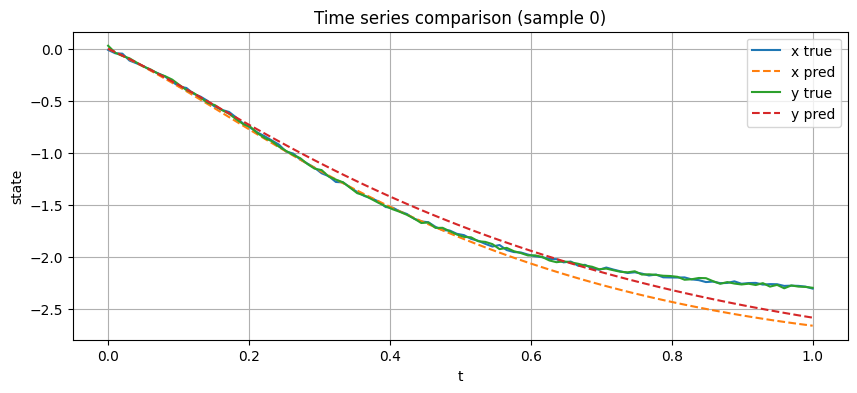

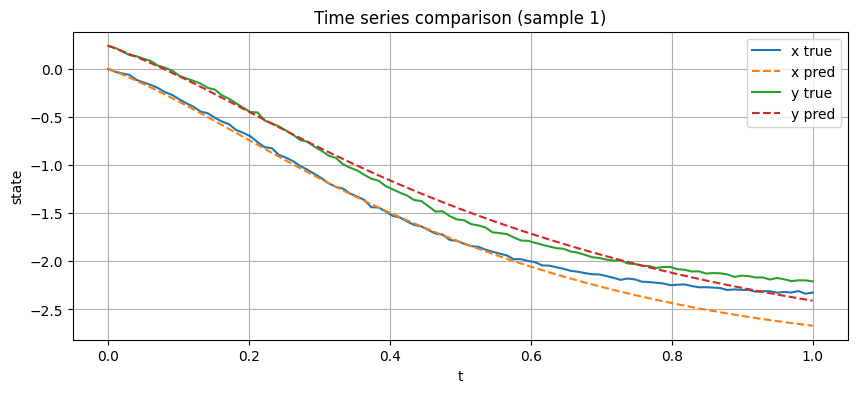

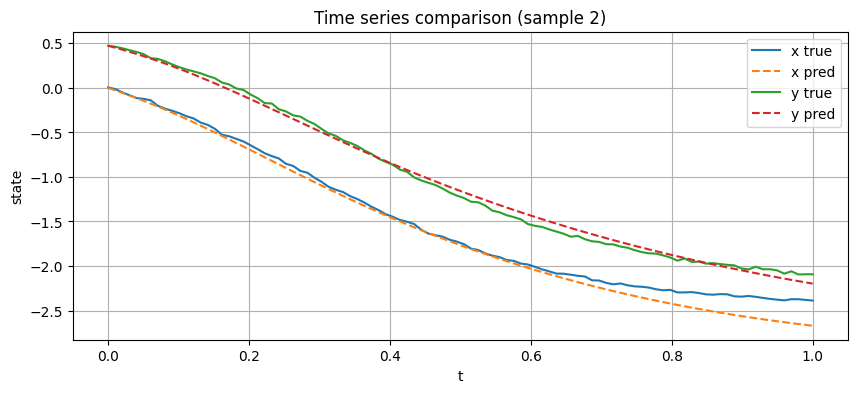

In [12]:
Z_pred_all = predict_traj(node, z0_all, t_eval)
plot_time_series(Z_all, Z_pred_all, t_eval, idx=0)
plot_time_series(Z_all, Z_pred_all, t_eval, idx=1)
plot_time_series(Z_all, Z_pred_all, t_eval, idx=2)

In [37]:
def plot_phase_comparison(true_Z, pred_Z, z0=None, n_samples=100, random_samples=True):
    plt.figure(figsize=(8, 8))

    N = true_Z.size(0)
    n = min(n_samples, N)

    if random_samples:
        idxs = torch.randperm(N)[:n]
    else:
        idxs = torch.arange(n)

    colors_true = plt.cm.Blues(np.linspace(0.35, 1.0, n))
    colors_pred = plt.cm.Reds(np.linspace(0.35, 1.0, n))

    for k, i in enumerate(idxs):
        i = i.item()

        true_np = true_Z[i].detach().cpu().numpy()
        pred_np = pred_Z[i].detach().cpu().numpy()

        c_true = colors_true[k]
        c_pred = colors_pred[k]

        if k == 0:
            plt.plot(
                true_np[:, 0], true_np[:, 1],
                color=c_true, lw=2, alpha=0.9,
                label="True trajectory"
            )
            plt.plot(
                pred_np[:, 0], pred_np[:, 1],
                "--", color=c_pred, lw=2, alpha=0.9,
                label="Neural ODE"
            )
        else:
            plt.plot(
                true_np[:, 0], true_np[:, 1],
                color=c_true, lw=2, alpha=0.9
            )
            plt.plot(
                pred_np[:, 0], pred_np[:, 1],
                "--", color=c_pred, lw=2, alpha=0.9
            )

        if z0 is not None:
            z0_np = z0[i].detach().cpu().numpy()
            if k == 0:
                plt.scatter(
                    z0_np[0], z0_np[1],
                    color="black", s=20, label="Initial state"
                )
            else:
                plt.scatter(
                    z0_np[0], z0_np[1],
                    color="black", s=20
                )

    plt.xlabel("x")
    plt.ylabel("y")
    plt.title("Phase portrait: true vs Neural ODE")
    plt.grid(True)
    plt.axis("equal")
    plt.legend()
    plt.show()

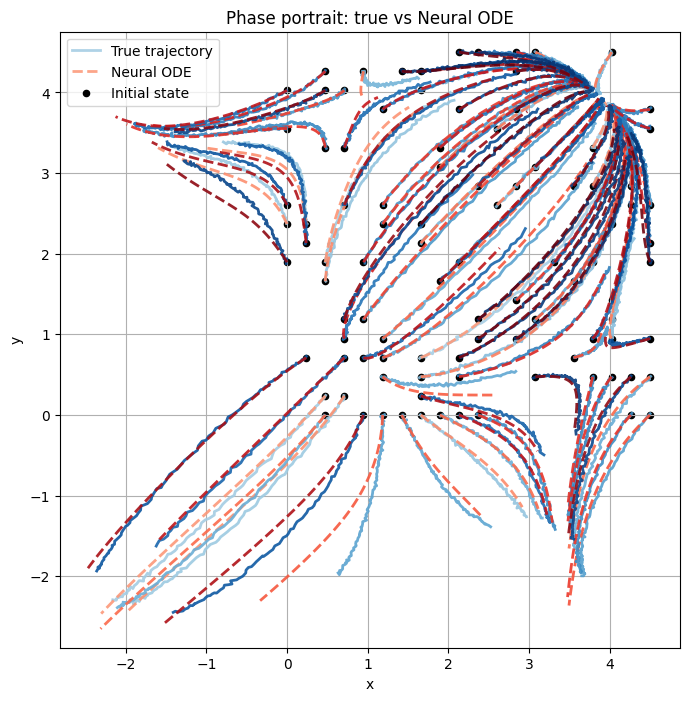

In [38]:
plot_phase_comparison(Z_all, Z_pred_all, z0=z0_all, n_samples=100, random_samples=True)

In [39]:

def plot_vector_field_overlay(true_func, learned_func,
                              xlim=(-3.0, 4.5), ylim=(-3.0, 4.5),
                              n=25, y_shift=0.06, normalize=False):
    x = np.linspace(xlim[0], xlim[1], n)
    y = np.linspace(ylim[0], ylim[1], n)
    X, Y = np.meshgrid(x, y)

    U_true = np.zeros_like(X)
    V_true = np.zeros_like(Y)
    U_pred = np.zeros_like(X)
    V_pred = np.zeros_like(Y)

    t0 = torch.tensor(0.0, device=device)

    for i in range(n):
        for j in range(n):
            z = torch.tensor([[X[i, j], Y[i, j]]], dtype=torch.float32, device=device)

            with torch.no_grad():
                vt = true_func(t0, z).squeeze(0).cpu().numpy()
                vp = learned_func(t0, z).squeeze(0).cpu().numpy()

            U_true[i, j], V_true[i, j] = vt[0], vt[1]
            U_pred[i, j], V_pred[i, j] = vp[0], vp[1]

    if normalize:
        mag_true = np.sqrt(U_true**2 + V_true**2) + 1e-8
        mag_pred = np.sqrt(U_pred**2 + V_pred**2) + 1e-8

        U_true, V_true = U_true / mag_true, V_true / mag_true
        U_pred, V_pred = U_pred / mag_pred, V_pred / mag_pred

    plt.figure(figsize=(9, 8))

    plt.quiver(X, Y, U_true, V_true, color='black', alpha=0.85, label='True system')
    plt.quiver(X, Y + y_shift, U_pred, V_pred, color='red', alpha=0.65,
               label=f'Learned system (shifted by +{y_shift} in y)')

    plt.title("Overlay of true and learned vector fields")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.xlim(xlim)
    plt.ylim(ylim[0], ylim[1] + y_shift + 0.1)
    plt.grid(True)
    plt.axis("equal")
    plt.legend()
    plt.show()

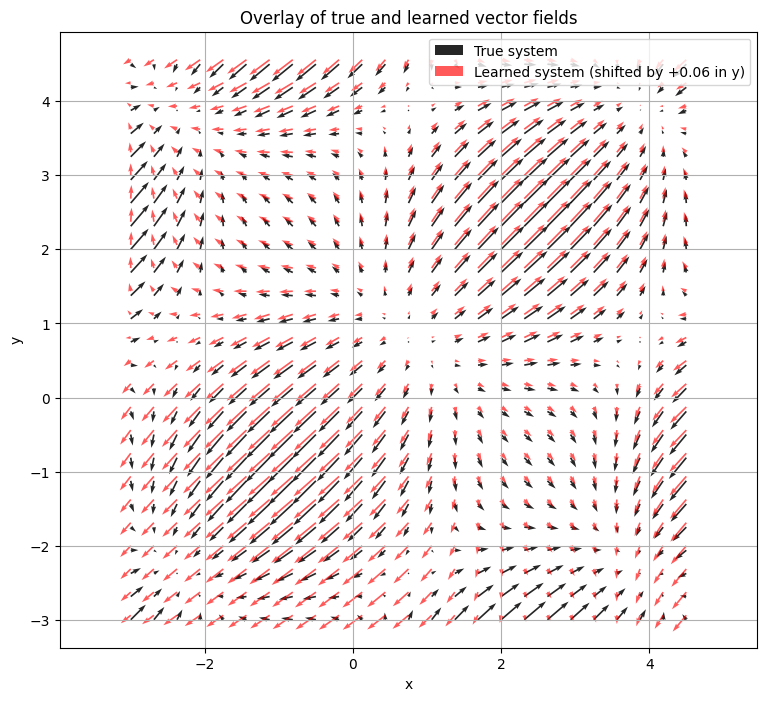

In [40]:
true_func = Cos().to(device)
learned_func = node.func

plot_vector_field_overlay(
    true_func,
    learned_func,
    xlim=(-3.0, 4.5),
    ylim=(-3.0, 4.5),
    n=25,
    y_shift=0.06,
    normalize=False
)

In [41]:
def plot_phase_with_equilibria(true_Z, pred_Z, equilibria, n_samples=30):
    plt.figure(figsize=(8, 8))

    n = min(n_samples, true_Z.size(0))
    for i in range(n):
        true_np = true_Z[i].detach().cpu().numpy()
        pred_np = pred_Z[i].detach().cpu().numpy()

        plt.plot(true_np[:, 0], true_np[:, 1], alpha=0.5)
        plt.plot(pred_np[:, 0], pred_np[:, 1], "--", alpha=0.5)

    if len(equilibria) > 0:
        eq = np.array([p.detach().cpu().numpy() for p in equilibria])
        plt.scatter(eq[:, 0], eq[:, 1], s=100, marker="x", label="Learned equilibria")

    plt.xlabel("x")
    plt.ylabel("y")
    plt.title("Phase portrait with equilibria")
    plt.grid(True)
    plt.legend()
    plt.show()

In [42]:
data1 = torch.load("equilibria_results.pt", map_location="cpu")

true_equilibria = data1["true_equilibria"]
pred_equilibria = data1["pred_equilibria"]
residuals = data1["residuals"]
starts = data1["starts"]

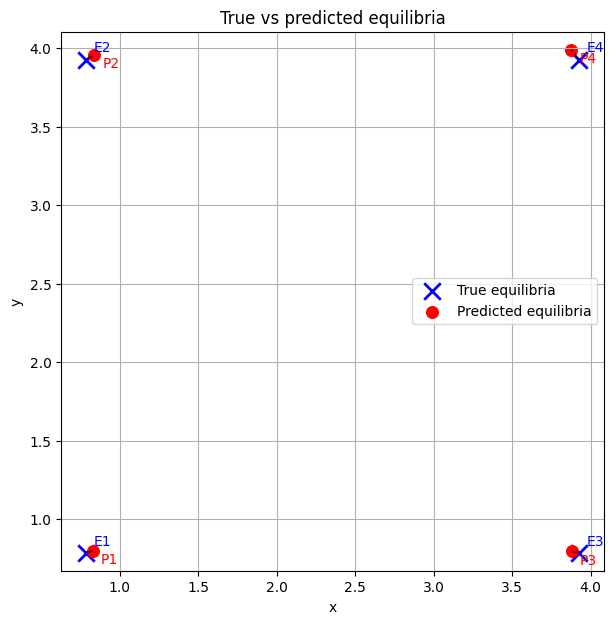

In [43]:
def plot_equilibria(true_equilibria, pred_equilibria, xlim=(-3, 4.5), ylim=(-3, 4.5)):
    true_np = true_equilibria.numpy()
    pred_np = pred_equilibria.numpy()

    plt.figure(figsize=(7, 7))

    plt.scatter(
        true_np[:, 0], true_np[:, 1],
        color="blue", marker="x", s=140, linewidths=2,
        label="True equilibria"
    )

    plt.scatter(
        pred_np[:, 0], pred_np[:, 1],
        color="red", marker="o", s=70,
        label="Predicted equilibria"
    )

    for i in range(len(true_np)):
        plt.plot(
            [true_np[i, 0], pred_np[i, 0]],
            [true_np[i, 1], pred_np[i, 1]],
            "k--", alpha=0.5
        )
        plt.text(true_np[i, 0] + 0.05, true_np[i, 1] + 0.05, f"E{i+1}", color="blue")
        plt.text(pred_np[i, 0] + 0.05, pred_np[i, 1] - 0.08, f"P{i+1}", color="red")

    plt.xlabel("x")
    plt.ylabel("y")
    plt.title("True vs predicted equilibria")
    plt.xlim(xlim)
    plt.ylim(ylim)
    plt.grid(True)
    plt.axis("equal")
    plt.legend()
    plt.show()

plot_equilibria(true_equilibria, pred_equilibria)